# Automated Captcha Testing – how it all works

This notebook walks through the whole project with real outputs:

1. [The captcha generator](#1-the-captcha-generator)
2. [Splitting data by label](#2-splitting-data-by-label)
3. [Preprocessing: any size in, fixed size out](#3-preprocessing-any-size-in-fixed-size-out)
4. [The model: CRNN](#4-the-model-crnn)
5. [CTC: reading without knowing where the letters are](#5-ctc-reading-without-knowing-where-the-letters-are)
6. [Training](#6-training)
7. [Results and failure cases](#7-results-and-failure-cases)
8. [Can we trust the confidence score?](#8-can-we-trust-the-confidence-score)
9. [Fine-tuning on your own captchas](#9-fine-tuning-on-your-own-captchas)
10. [API and Playwright end-to-end test](#10-api-and-playwright-end-to-end-test)

The outputs are saved, so it reads fine without running anything. To run it yourself you need the
datasets and checkpoints from the README's quick start (`data/text_v1`, `data/text_v2`,
`checkpoints/text_v1`, `checkpoints/text_v1_ft`, `checkpoints/text_v2`, and for section 9 `data/user_demo`,
`checkpoints/user_demo`).

In [1]:
import json
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageFilter

from captchagen import CaptchaGenerator, GeneratorConfig
from captchagen.metrics import SequenceMetrics
from captchagen.model import CRNN, greedy_decode
from captchagen.preprocess import FitToBox
from captchagen.splits import split_for_label
from predict import CaptchaReader

plt.rcParams.update({"figure.dpi": 90, "axes.grid": False, "font.size": 10})
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


def show(images, titles=None, cols=3, width=12):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(width, 1.9 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

device: cuda


## 1. The captcha generator

`captchagen/generator.py` draws a captcha from a label (random text, or a math expression such as
`37+5`). One **difficulty** number from 1 to 5 is turned into a strength `t = (difficulty - 1) / 4`
between 0 and 1, and every effect scales with it: rotation, shear and overlap of the characters,
gradient backgrounds, dots and arcs, lines through the text, a sine-wave warp, grain and blur.

Here is the same text at every level:

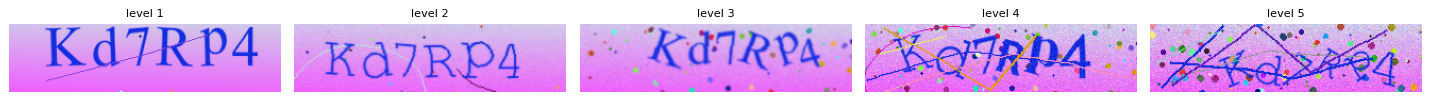

In [2]:
gen = CaptchaGenerator(seed=0)
samples = [gen.generate(index=7, difficulty=level, text="Kd7Rp4") for level in range(1, 6)]
show([s.image for s in samples], [f"level {s.difficulty}" for s in samples], cols=5, width=16)

### Anatomy of one captcha

`generate()` is a fixed sequence of steps, each using the same random number generator. Running the
steps by hand shows what each one adds, and the last line checks that the result is pixel-for-pixel
what `generate()` returns: every image is fully determined by `(seed, index, difficulty)`, which makes
datasets reproducible.

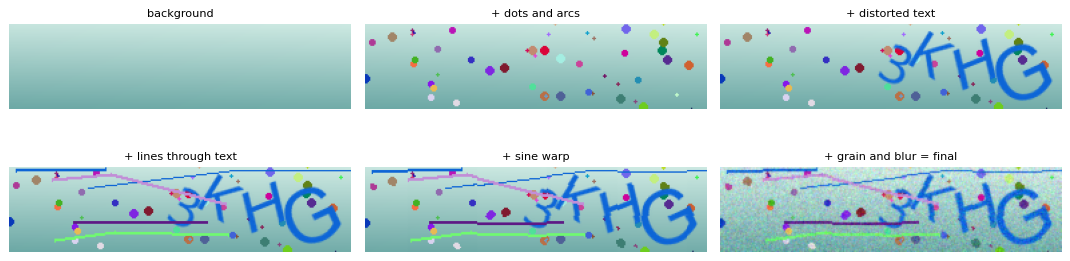

label: '3KHG'   identical to generate(): True


In [3]:
g = CaptchaGenerator(seed=0)
index, level = 42, 5
t = (level - 1) / 4
rng = random.Random(g.seed * 1_000_003 + index)
np_rng = np.random.default_rng(g.seed * 1_000_003 + index)

text, _ = g._random_label(rng, level)
w, h = g._canvas_size(rng)
img = g._background(rng, t, w, h);                                     steps = [("background", img.copy())]
color = g._text_color(rng, img)          # picked to contrast with the background
g._draw_noise(img, rng, t, under_text=True);                           steps.append(("+ dots and arcs", img.copy()))
g._paste_centered(img, g._render_text(text, rng, t, color, h), rng, t); steps.append(("+ distorted text", img.copy()))
g._draw_noise(img, rng, t, under_text=False, text_color=color);        steps.append(("+ lines through text", img.copy()))
img = g._warp(img, np_rng, rng, t);                                    steps.append(("+ sine warp", img))
img = g._speckle(img, np_rng, t)
if rng.random() < 0.3 + 0.5 * t:
    img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0.3, 0.4 + 0.9 * t)))
steps.append(("+ grain and blur = final", img))

show([s[1] for s in steps], [s[0] for s in steps], cols=3)
same = np.array_equal(np.asarray(img), np.asarray(g.generate(index, level).image))
print(f"label: {text!r}   identical to generate(): {same}")

### Math mode, sizes and styles

Math captchas store the answer next to the label. `random_size` gives every image its own canvas
(height 32–140 px, aspect ratio 1.8–6), and `style_variety` adds 29 italic and handwriting fonts,
hollow / bold / thin letters and grid backgrounds.

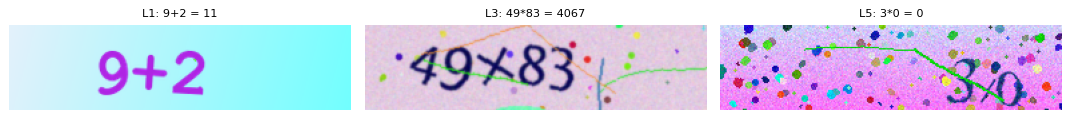

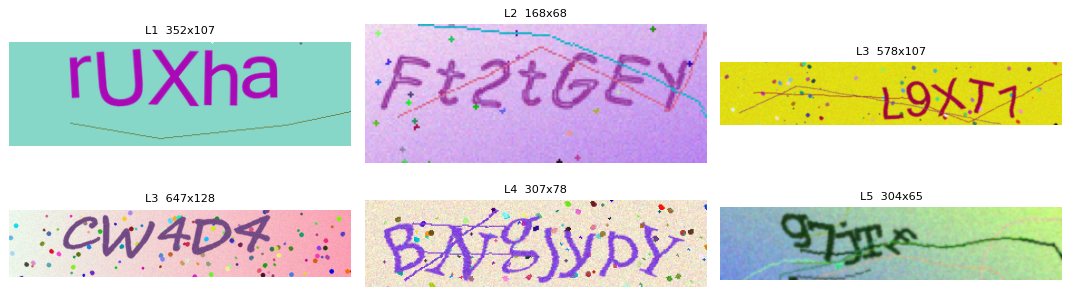

In [4]:
mgen = CaptchaGenerator(GeneratorConfig(mode="math"), seed=3)
m = [mgen.generate(i, level) for i, level in enumerate([1, 3, 5])]
show([s.image for s in m], [f"L{s.difficulty}: {s.text} = {s.answer}" for s in m], cols=3)

varied = CaptchaGenerator(GeneratorConfig(random_size=True, style_variety=True), seed=2)
v = [varied.generate(1000 * level + i, level) for i, level in enumerate([1, 2, 3, 3, 4, 5])]
show([s.image for s in v], [f"L{s.difficulty}  {s.image.width}x{s.image.height}" for s in v], cols=3)

## 2. Splitting data by label

The first version of this project used a third-party generator: 60,000 math images, but only about
12,000 different equations, split randomly **by image**. Then the test set is mostly equations the model
already saw in training, just drawn differently – the accuracy looks better than it is:

In [5]:
old = Path("image_data.csv")
if old.exists():
    eq = pd.read_csv(old, dtype=str).equation
    shuffled = eq.sample(frac=1, random_state=0)
    train, test = shuffled[:48000], shuffled[48000:]
    seen = test.isin(set(train)).mean()
    print(f"{len(eq)} images, {eq.nunique()} different equations")
    print(f"random 80/20 split by image: {seen:.0%} of test images have an equation that is also in train")
else:
    print("(old dataset not present)")

60000 images, 11977 different equations
random 80/20 split by image: 97% of test images have an equation that is also in train


Now every label goes to train, val or test by a **hash of its text** (`captchagen/splits.py`), so all
drawings of the same string land in the same split, and test strings are never seen in training. The
on-the-fly dataset uses the same rule: when it draws a label that belongs to val/test, it draws again.

In [6]:
print({t: split_for_label(t) for t in ["A2b9", "Kd7Rp4", "37+5", "hello"]})

labels = pd.read_csv("data/text_v1/labels.csv", dtype={"text": str})
sets = {s: set(labels.text[labels.split == s]) for s in ["train", "val", "test"]}
print(labels.split.value_counts().to_dict())
print("labels in both train and test:", len(sets["train"] & sets["test"]))
print("labels in both train and val: ", len(sets["train"] & sets["val"]))

{'A2b9': 'val', 'Kd7Rp4': 'test', '37+5': 'train', 'hello': 'train'}
{'train': 89956, 'test': 5034, 'val': 5010}
labels in both train and test: 0
labels in both train and val:  0


## 3. Preprocessing: any size in, fixed size out

The model always takes a 64×256 grayscale image. Stretching every input to that size squashes wide
captchas and smears narrow ones. `FitToBox` (`captchagen/preprocess.py`) scales the image to fit
**keeping its aspect ratio** and fills the rest with the image's own border color. The same function
is used for training, `predict.py` and the API. On varied-size images this alone raised accuracy from
65.9% to 79.4%, before any retraining.

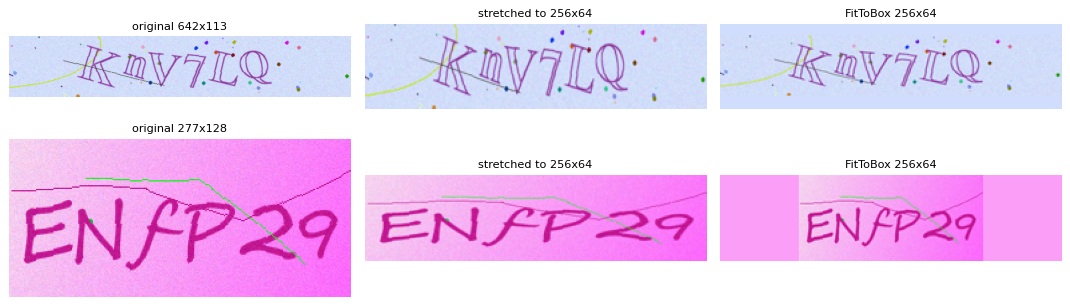

In [7]:
wide = varied.generate(4001, 3)
narrow = next(s for i in range(4100, 4200) if (s := varied.generate(i, 2)).image.width / s.image.height < 2.2)
fit = FitToBox(256, 64)
show([wide.image, wide.image.resize((256, 64)), fit(wide.image),
      narrow.image, narrow.image.resize((256, 64)), fit(narrow.image)],
     [f"original {wide.image.width}x{wide.image.height}", "stretched to 256x64", "FitToBox 256x64",
      f"original {narrow.image.width}x{narrow.image.height}", "stretched to 256x64", "FitToBox 256x64"], cols=3)

## 4. The model: CRNN

A **CRNN** (convolutional recurrent neural network) is the standard architecture for reading a line
of text:

- **CNN**: 7 conv blocks (conv → BatchNorm → ReLU). The first two poolings halve height and width; the
  later ones only halve the **height**, so the image ends up as 64 columns, each described by 512 numbers.
- **BiLSTM**: reads those 64 columns left→right and right→left, so each column knows its neighbors
  (useful when characters overlap).
- **Linear**: per column, a score for each character plus one extra class, the CTC "blank".

In [8]:
reader = CaptchaReader("checkpoints/text_v2/best.pth", device)
model = reader.model
print(f"vocabulary ({len(reader.vocab.chars)} chars): {reader.vocab.chars}")
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M\n")

x = torch.zeros(1, 1, 64, 256, device=device)
print(f"{'input':<28}{tuple(x.shape)}")
with torch.no_grad():
    for layer in model.cnn:
        x = layer(x)
        if isinstance(layer, (torch.nn.MaxPool2d, torch.nn.AdaptiveAvgPool2d)):
            print(f"{'after ' + type(layer).__name__:<28}{tuple(x.shape)}")
    seq = x.squeeze(2).permute(2, 0, 1)
    print(f"{'as a sequence [T, B, F]':<28}{tuple(seq.shape)}")
    seq, _ = model.rnn(seq)
    print(f"{'after BiLSTM':<28}{tuple(seq.shape)}")
    print(f"{'class scores [T, B, C]':<28}{tuple(model.classifier(seq).shape)}")

vocabulary (46 chars): 23456789ABCDEFGHJKLMNPQRTUVWXYabdefghjkmnpqrty
parameters: 10.0M

input                       (1, 1, 64, 256)
after MaxPool2d             (1, 64, 32, 128)


after MaxPool2d             (1, 128, 16, 64)
after MaxPool2d             (1, 256, 8, 64)
after MaxPool2d             (1, 512, 4, 64)
after AdaptiveAvgPool2d     (1, 512, 1, 64)
as a sequence [T, B, F]     (64, 1, 512)
after BiLSTM                (64, 1, 512)
class scores [T, B, C]      (64, 1, 47)


## 5. CTC: reading without knowing where the letters are

The labels say *what* the text is, not *where* each character is. **CTC (Connectionist Temporal
Classification)** solves this: the model predicts a character or a *blank* for each of the 64
columns, and a column sequence is turned into text by

1. merging repeated characters, then
2. dropping blanks.

So `--KK-dd--77-RR-pp--44--` becomes `Kd7Rp4`. A blank between two equal characters keeps both
(`l-l` → `ll`). The CTC loss sums the probability of *every* column sequence that collapses to the
label, so training never needs character positions.

In [9]:
def collapse(columns):
    out, prev = [], None
    for c in columns:
        if c != "-" and c != prev:
            out.append(c)
        prev = c
    return "".join(out)

for columns in ["--KK-dd--77-RR-pp--44--", "-hh-e-ll-ll-oo-", "-hh-e-llll-oo-"]:
    print(f"{columns:<26} -> {collapse(columns)}")

--KK-dd--77-RR-pp--44--    -> Kd7Rp4
-hh-e-ll-ll-oo-            -> hello
-hh-e-llll-oo-             -> helo


And here is what the trained model actually outputs for one captcha. Each bar is one of the 64 columns:
gray bars are columns where the most likely class is *blank*, colored bars are characters (with the
character written above). The model "fires" each character in roughly one or two columns where that
character is drawn, and outputs blank everywhere else.

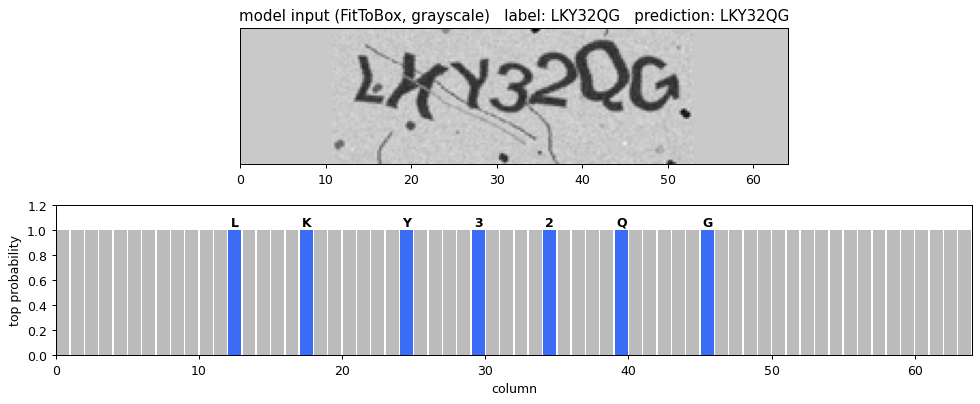

In [10]:
sample = CaptchaGenerator(GeneratorConfig(random_size=True, style_variety=True), seed=11).generate(5, 4)
x = reader.transform(sample.image).unsqueeze(0).to(device)
with torch.no_grad():
    log_probs = model(x)[:, 0]                       # [64 columns, classes]
probs = log_probs.exp().cpu()
best_p, best_c = probs.max(1)
pred = reader.vocab.decode(greedy_decode(log_probs.unsqueeze(1))[0])

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.6), gridspec_kw={"height_ratios": [1, 1.1]})
a1.imshow(x[0, 0].cpu(), cmap="gray", extent=(0, 64, 0, 16))
a1.set_title(f"model input (FitToBox, grayscale)   label: {sample.text}   prediction: {pred}")
a1.set_yticks([]); a1.set_xlim(0, 64)
colors = ["#bbbbbb" if c == 0 else "#3b6cf6" for c in best_c]
a2.bar(np.arange(64) + 0.5, best_p, width=0.9, color=colors)
for i, (p, c) in enumerate(zip(best_p, best_c)):
    if c != 0:
        a2.text(i + 0.5, p + 0.03, reader.vocab.chars[c - 1], ha="center", fontsize=10, weight="bold")
a2.set_xlim(0, 64); a2.set_ylim(0, 1.2); a2.set_xlabel("column"); a2.set_ylabel("top probability")
plt.tight_layout(); plt.show()

## 6. Training

`train.py` uses AdamW with a one-cycle learning rate, mixed precision (with the CTC loss in fp32,
where fp16 is unstable), gradient clipping, and a **curriculum**: the first run starts on level 1 and
unlocks one level at a time over the first 30% of epochs. Three runs led to the final model:

| run | data | what it fixed |
|---|---|---|
| `text_v1` | 90k fixed images on disk, 30 epochs | the baseline |
| `text_v1_ft` | **new generated images every epoch**, hard levels sampled more, 20 epochs | it was memorizing: training loss 0.01 while level 5 stalled |
| `text_v2` | new images in **random sizes and styles**, 20 epochs | robustness to any input size and font |

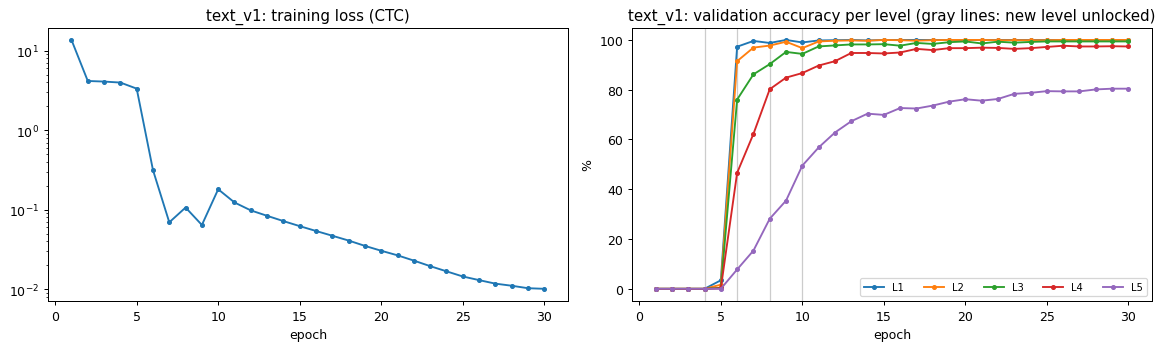

In [11]:
def history(name):
    return json.loads(Path(f"checkpoints/{name}/history.json").read_text())

h = history("text_v1")
epochs = [e["epoch"] for e in h]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(epochs, [e["loss"] for e in h], marker=".")
a1.set_yscale("log"); a1.set_title("text_v1: training loss (CTC)"); a1.set_xlabel("epoch")
for level in "12345":
    a2.plot(epochs, [100 * e["val"]["levels"].get(level, {}).get("accuracy", np.nan) for e in h],
            marker=".", label=f"L{level}")
for e in h:
    if e["epoch"] > 1 and len(e["levels"]) > len(h[e["epoch"] - 2]["levels"]):
        a2.axvline(e["epoch"], color="#ccc", lw=1, zorder=0)
a2.set_title("text_v1: validation accuracy per level (gray lines: new level unlocked)")
a2.set_xlabel("epoch"); a2.set_ylabel("%"); a2.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

CTC models usually sit on a plateau first (loss ≈ 4 above: the model outputs mostly blanks), then
suddenly "click" and accuracy jumps – here from 1% to 63% in one epoch. Every time a harder level is
unlocked, the easy levels dip briefly and recover.

The fine-tunes, level 5 in particular:

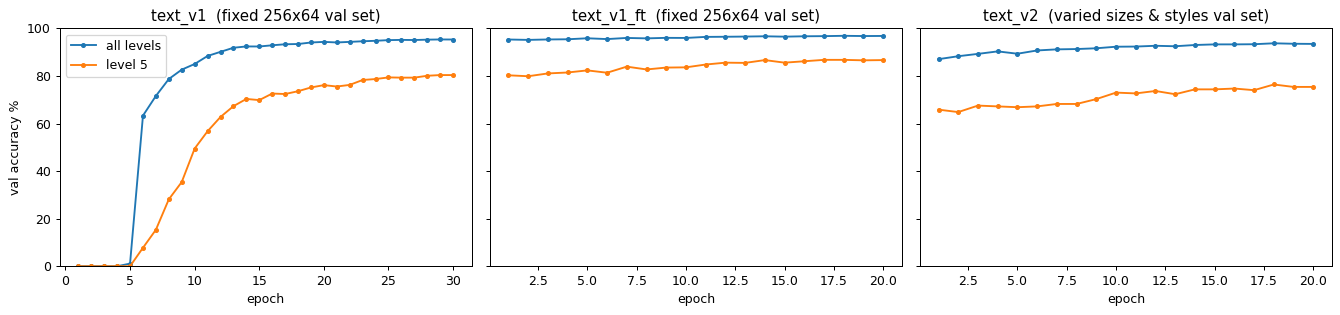

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, name, note in [(axes[0], "text_v1", "fixed 256x64 val set"),
                       (axes[1], "text_v1_ft", "fixed 256x64 val set"),
                       (axes[2], "text_v2", "varied sizes & styles val set")]:
    h = history(name)
    ep = [e["epoch"] for e in h]
    ax.plot(ep, [100 * e["val"]["overall"]["accuracy"] for e in h], marker=".", label="all levels")
    ax.plot(ep, [100 * e["val"]["levels"].get("5", {}).get("accuracy", np.nan) for e in h], marker=".", label="level 5")
    ax.set_title(f"{name}  ({note})"); ax.set_xlabel("epoch")
axes[0].set_ylabel("val accuracy %"); axes[0].legend(); axes[0].set_ylim(0, 100)
plt.tight_layout(); plt.show()

## 7. Results and failure cases

Exact-match accuracy (every character right) on the **test** splits, which no checkpoint ever trained
or selected on.

In [13]:
def predict_split(reader, root, split="test", batch=128):
    df = pd.read_csv(f"{root}/labels.csv", dtype={"text": str})
    df = df[df.split == split].reset_index(drop=True)
    preds = []
    for i in range(0, len(df), batch):
        imgs = [Image.open(f"{root}/images/{f}") for f in df.filename[i:i + batch]]
        preds += reader.read(imgs)
    df["pred"] = [p.text for p in preds]
    df["confidence"] = [p.confidence for p in preds]
    df["correct"] = df.pred == df.text
    return df


def by_level(df):
    m = SequenceMetrics(); m.update(list(df.pred), list(df.text))
    row = {("real" if l == 0 else f"L{l}"): f"{100 * g.correct.mean():.1f}%" for l, g in df.groupby("difficulty")}
    row.update({"overall": f"{100 * m.accuracy:.1f}%", "char error rate": f"{100 * m.cer:.2f}%"})
    return row


readers = {name: CaptchaReader(f"checkpoints/{name}/best.pth", device) for name in ["text_v1", "text_v1_ft", "text_v2"]}
results = {(name, ds): predict_split(r, f"data/{ds}") for name, r in readers.items() for ds in ["text_v1", "text_v2"]}
table = pd.DataFrame({f"{name} on {ds}": by_level(df) for (name, ds), df in results.items()}).T
table

,L1,L2,L3,L4,L5,overall,char error rate
text_v1 on text_v1,99.9%,99.9%,99.6%,97.5%,80.9%,95.5%,1.04%
text_v1 on text_v2,86.4%,85.1%,83.1%,75.8%,59.4%,78.3%,7.19%
text_v1_ft on text_v1,99.9%,99.9%,99.6%,98.8%,87.2%,97.0%,0.65%
text_v1_ft on text_v2,86.8%,86.4%,84.1%,76.9%,60.9%,79.3%,6.81%
text_v2 on text_v1,100.0%,99.8%,99.3%,98.4%,83.1%,96.0%,0.88%
text_v2 on text_v2,98.9%,99.7%,96.8%,93.5%,79.3%,93.9%,1.62%


Reading the table: each fine-tune improved what it targeted. `text_v2` handles varied sizes and fonts
(79% → 94%) at a small cost on the fixed-size set's level 5. Here are some captchas the final model
gets wrong – most are genuinely hard to read for a human too:

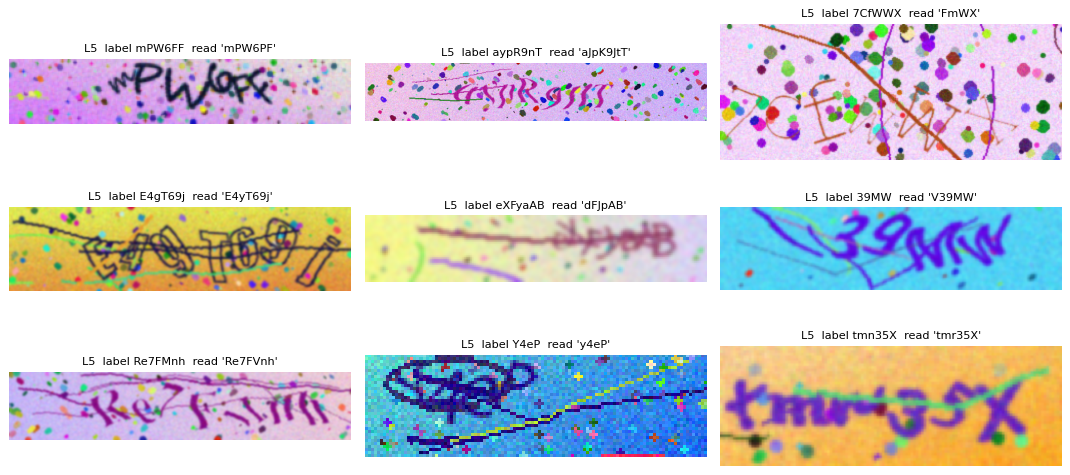

In [14]:
fails = results[("text_v2", "text_v2")]
fails = fails[~fails.correct].sort_values("difficulty", ascending=False).head(9)
show([Image.open(f"data/text_v2/images/{f}") for f in fails.filename],
     [f"L{d}  label {t}  read {p!r}" for d, t, p in zip(fails.difficulty, fails.text, fails.pred)], cols=3)

## 8. Can we trust the confidence score?

The confidence is the probability of the decoded column path: the product of the top probability in
all 64 columns. One unsure column is enough to pull it down. If it's meaningful, low-confidence
predictions should be wrong much more often:

In [15]:
df = results[("text_v2", "text_v2")]
bins = [0, 0.3, 0.5, 0.7, 0.9, 0.99, 1.0001]
df["bucket"] = pd.cut(df.confidence, bins, right=False)
calib = df.groupby("bucket", observed=True).agg(images=("correct", "size"), accuracy=("correct", "mean"))
calib["accuracy"] = (100 * calib.accuracy).round(1)
print(calib, "\n")
for threshold in [0.5, 0.9]:
    keep = df.confidence >= threshold
    print(f"answer only when confidence >= {threshold}: answers {keep.mean():.0%} of captchas, "
          f"{100 * df.correct[keep].mean():.1f}% of those right (vs {100 * df.correct.mean():.1f}% overall)")

             images  accuracy
bucket                       
[0.0, 0.3)       43      11.6
[0.3, 0.5)       40      45.0
[0.5, 0.7)      116      89.7
[0.7, 0.9)      170      92.9
[0.9, 0.99)     342      98.8
[0.99, 1.0)     727     100.0 

answer only when confidence >= 0.5: answers 94% of captchas, 97.9% of those right (vs 93.9% overall)
answer only when confidence >= 0.9: answers 74% of captchas, 99.6% of those right (vs 93.9% overall)


## 9. Fine-tuning on your own captchas

`import_dataset.py` turns a folder of labeled images (label in the file name, or a CSV) into a dataset,
split by label like everything else. `train.py --init` then fine-tunes the model on it, with two tricks:

- **Vocabulary extension.** If your captchas use characters the model never learned (`0`, `O`, `1`…),
  the output layer is rebuilt for the union of both character sets: the blank and every known character
  keep their trained weights, new characters start fresh. The CNN and LSTM keep everything.
- **`--mix-synthetic`** adds generated images to every epoch, so a small labeled set isn't memorized and
  the old skills aren't forgotten.

Demo: 2,000 captchas in a style the model had never seen (full alphanumeric set with 16 new
characters, 200×70), 1,611 used for training, 25 epochs (~25 minutes):

In [16]:
demo = CaptchaReader("checkpoints/user_demo/best.pth", device)
added = sorted(set(demo.vocab.chars) - set(reader.vocab.chars))
print(f"vocabulary {len(reader.vocab.chars)} -> {len(demo.vocab.chars)} characters, added: {''.join(added)}\n")

before = predict_split(reader, "data/user_demo")
after = predict_split(demo, "data/user_demo")
still = predict_split(demo, "data/text_v2")
pd.DataFrame({"text_v2 (before)": {"their test set": f"{100 * before.correct.mean():.1f}%",
                                   "our varied test set": f"{100 * results[('text_v2', 'text_v2')].correct.mean():.1f}%"},
              "user_demo (after)": {"their test set": f"{100 * after.correct.mean():.1f}%",
                                    "our varied test set": f"{100 * still.correct.mean():.1f}%"}})

vocabulary 46 -> 62 characters, added: 01IOSZcilosuvwxz



,text_v2 (before),user_demo (after)
their test set,18.2%,80.8%
our varied test set,93.9%,94.0%


In [17]:
confusions = Counter()
for t, p in zip(after.text, after.pred):
    if t != p and len(t) == len(p):
        confusions.update(f"{a} read as {b}" for a, b in zip(t, p) if a != b)
print("most common mistakes:", confusions.most_common(8))

most common mistakes: [('l read as 1', 5), ('I read as l', 5), ('w read as W', 4), ('l read as I', 3), ('o read as O', 3), ('Z read as z', 2), ('s read as S', 2), ('O read as 0', 2)]


The remaining mistakes are look-alikes (`l`/`1`/`I`, `O`/`0`/`o`) and case pairs – the reason most
captchas, and this project's default charset, leave those characters out.

## 10. API and Playwright end-to-end test

`server.py` (FastAPI, bound to `127.0.0.1`):

| endpoint | what it does |
|---|---|
| `GET /` | upload page: drag in images, see text and confidence |
| `POST /api/predict` | multipart `files` → text, confidence, answer (math), image size; size and pixel limits |
| `GET /challenge` | a captcha form served from our generator |
| `GET /api/challenge`, `POST /api/verify` | one-shot challenges that expire after 5 minutes |

`e2e_captcha_test.py` drives a real Chromium with Playwright: it opens `/challenge`, the model reads the
captcha (from the image, or from a screenshot of what the browser rendered with `--screenshot`), types
the answer, submits and records the result. That turns "how good is the model" into "how often does a
bot get through my captcha":

```bash
python e2e_captcha_test.py --start-server --rounds 20
```

In [18]:
e2e = json.loads(Path("e2e_results.json").read_text())
print("model:", e2e["checkpoint"])
pd.DataFrame({f"L{l}": {"passed": s["passed"], "tried": s["total"], "pass rate": f"{100 * s['passed'] / s['total']:.0f}%"}
              for l, s in e2e["levels"].items()}).T

model: checkpoints/text_v2/best.pth


,passed,tried,pass rate
L1,20,20,100%
L2,20,20,100%
L3,19,20,95%
L4,19,20,95%
L5,18,20,90%


## Takeaways

- A plain distorted-text captcha is **not a serious obstacle**: a 10M-parameter model trained only on
  synthetic images passes 96% of challenges end to end, and 90% even at the hardest level.
- **How you split the data matters** as much as the model: splitting by image instead of by label
  would have reported inflated numbers.
- The biggest gains came from **data, not architecture**: fresh images every epoch fixed memorization,
  and aspect-preserving resizing plus varied sizes and fonts fixed robustness.
- With a few thousand labeled examples, the model **adapts to a new captcha style** in under half an hour.